# 01 — Data quality for uploaded traffic series

## Problem
Confirm that the new CSVs contain real timestamped sensor measurements and check sensor coverage, time cadence, missing values, and available metadata.

## Solution
Inspect METR-LA and PEMS-BAY directly. Zero speeds are counted as missing measurements; they are not treated as valid zero-speed traffic.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
REPORT = ROOT / 'report'
for folder in [FIG, METRICS, REPORT]:
    folder.mkdir(parents=True, exist_ok=True)

inventory = []
for name in ['METR-LA', 'PEMS-BAY']:
    frame = pd.read_csv(DATA / f'{name}.csv', index_col=0, parse_dates=True)
    values = frame.apply(pd.to_numeric, errors='coerce')
    observed = values.where(values > 0)
    gaps = frame.index.to_series().diff().dropna()
    inventory.append({
        'dataset': name, 'time_steps': len(frame), 'sensors': len(frame.columns),
        'start': frame.index.min(), 'end': frame.index.max(),
        'median_interval_minutes': gaps.median().total_seconds() / 60,
        'intervals_over_5min': int((gaps > pd.Timedelta(minutes=5)).sum()),
        'missing_or_zero_percent': float(observed.isna().to_numpy().mean() * 100),
        'observed_min_speed': float(observed.min().min()),
        'observed_max_speed': float(observed.max().max())
    })
    print(f'{name}: {frame.shape[0]:,} timestamps x {frame.shape[1]} sensors; five-minute speed series')

inventory = pd.DataFrame(inventory)
meta_path = DATA / 'PEMS-BAY-META.csv'
meta_match = False
if meta_path.exists():
    meta = pd.read_csv(meta_path, dtype={'sensor_id': str})
    bay_ids = pd.read_csv(DATA / 'PEMS-BAY.csv', nrows=0).columns[1:].astype(str)
    meta_match = set(meta['sensor_id']) == set(bay_ids)
    print(f'PEMS-BAY metadata sensors: {len(meta)} | exact ID match: {meta_match}')

inventory.to_csv(METRICS / 'traffic_data_quality.csv', index=False)
display(inventory.round(3))
print('LA graph adjacency available:', (DATA / 'sensor_graph' / 'adj_mx.pkl').exists())
print('Pretrained METR-LA checkpoint available:', (DATA / 'model' / 'pretrained' / 'METR-LA' / 'models-2.7422-24375.index').exists())
print('Traffic measures available: speed only; flow and occupancy are absent.')

METR-LA: 34,272 timestamps x 207 sensors; five-minute speed series


PEMS-BAY: 52,116 timestamps x 325 sensors; five-minute speed series
PEMS-BAY metadata sensors: 325 | exact ID match: True


,dataset,time_steps,sensors,start,end,median_interval_minutes,intervals_over_5min,missing_or_zero_percent,observed_min_speed,observed_max_speed
0,METR-LA,34272,207,2012-03-01,2012-06-27 23:55:00,5.0,0,8.109,0.333,70.0
1,PEMS-BAY,52116,325,2017-01-01,2017-06-30 23:55:00,5.0,1,0.003,3.000,85.1


LA graph adjacency available: False
Pretrained METR-LA checkpoint available: False
Traffic measures available: speed only; flow and occupancy are absent.


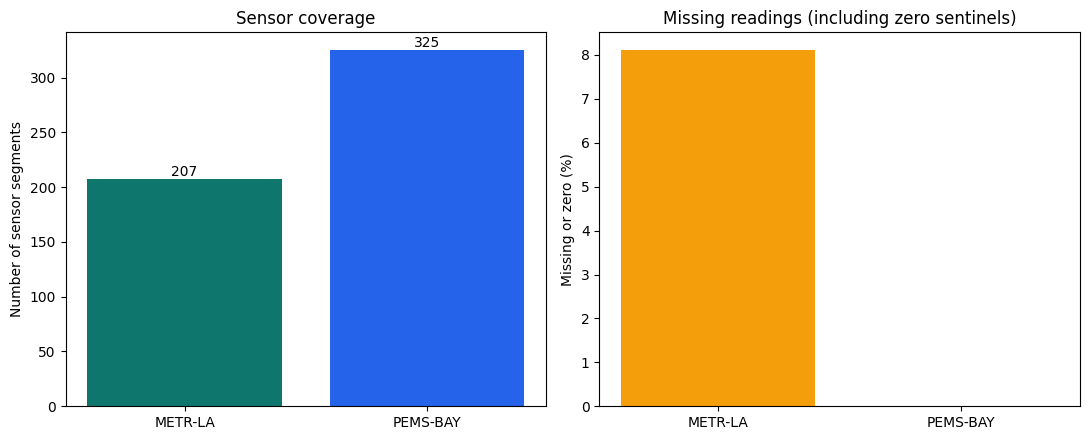

Saved results/figures/01_traffic_data_quality.png


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(inventory['dataset'], inventory['sensors'], color=['#0f766e', '#2563eb'])
axes[0].set(title='Sensor coverage', ylabel='Number of sensor segments')
for bar, value in zip(axes[0].patches, inventory['sensors']):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 3, str(value), ha='center')
axes[1].bar(inventory['dataset'], inventory['missing_or_zero_percent'], color=['#f59e0b', '#7c3aed'])
axes[1].set(title='Missing readings (including zero sentinels)', ylabel='Missing or zero (%)')
fig.tight_layout()
fig.savefig(FIG / '01_traffic_data_quality.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved results/figures/01_traffic_data_quality.png')